In [1]:
from skimage import data
import inspect
import matplotlib.pyplot as plt

# List all public callables in skimage.data
image_funcs = [
    name for name, obj in inspect.getmembers(data, inspect.isfunction)
    if not name.startswith("_")
]

print(image_funcs)

['astronaut', 'binary_blobs', 'brain', 'brick', 'camera', 'cat', 'cell', 'cells3d', 'checkerboard', 'chelsea', 'clock', 'coffee', 'coins', 'colorwheel', 'download_all', 'eagle', 'file_hash', 'grass', 'gravel', 'horse', 'hubble_deep_field', 'human_mitosis', 'immunohistochemistry', 'kidney', 'lbp_frontal_face_cascade_filename', 'lfw_subset', 'lily', 'logo', 'microaneurysms', 'moon', 'nickel_solidification', 'page', 'palisades_of_vogt', 'protein_transport', 'retina', 'rocket', 'shepp_logan_phantom', 'skin', 'stereo_motorcycle', 'text', 'vortex']


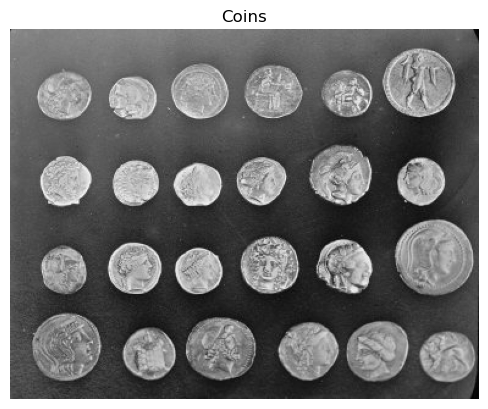

In [2]:
image_coins = data.coins()
#visualizing images
def show_image(image, title='Image', cmap_type='gray'):
    plt.imshow(image, cmap=cmap_type)
    plt.title(title)
    plt.axis('off')
    plt.show()

show_image(image_coins, "Coins")

# Edge Detection

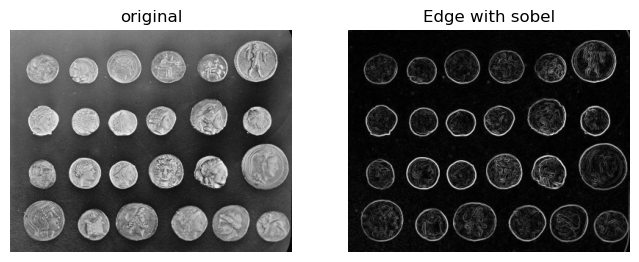

In [4]:
from skimage.filters import sobel
#apply edge detection filter
edge_sobel = sobel(image_coins)
#plot comparison function
#plot original and filtered image
def plot_comparison(original, filtered, title_filtered):
    fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(8,6), sharex=True, sharey=True)
    ax1.imshow(original, cmap=plt.cm.gray)
    ax1.set_title('original')
    ax1.axis('off')
    ax2.imshow(filtered, cmap=plt.cm.gray)
    ax2.set_title(title_filtered)
    ax2.axis('off')

plot_comparison(image_coins, edge_sobel, "Edge with sobel")

# Gaussian Smoothing

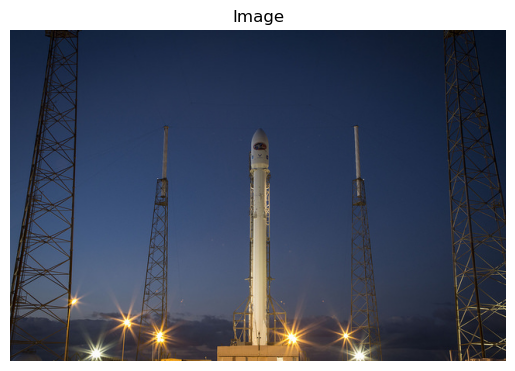

In [6]:
gauss_pic = data.rocket()
show_image(gauss_pic, 'Image')

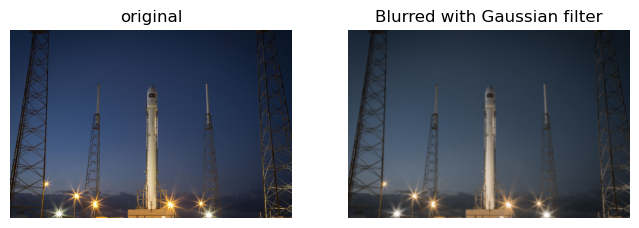

In [7]:
from skimage.filters import gaussian
# apply edge detection filter
gaussian_image = gaussian(gauss_pic)
plot_comparison(gauss_pic, gaussian_image, 'Blurred with Gaussian filter')

# Contrast Enhancement
contrast of an image -> spread of its histogram

Histogram equalization -> spreads out the most frequent histogram intensity values

C:\Users\hp\anaconda3\Lib\site-packages\skimage\_shared\utils.py:438: UserWarning: This might be a color image. The histogram will be computed on the flattened image. You can instead apply this function to each color channel, or set channel_axis.
  return func(*args, **kwargs)


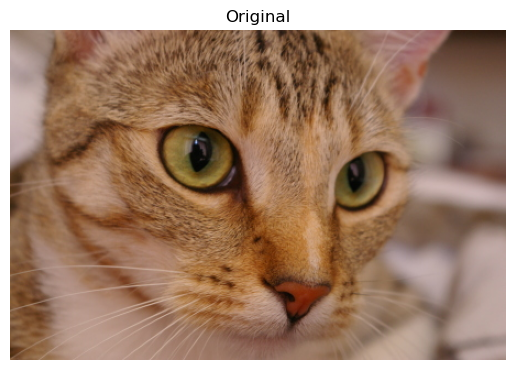

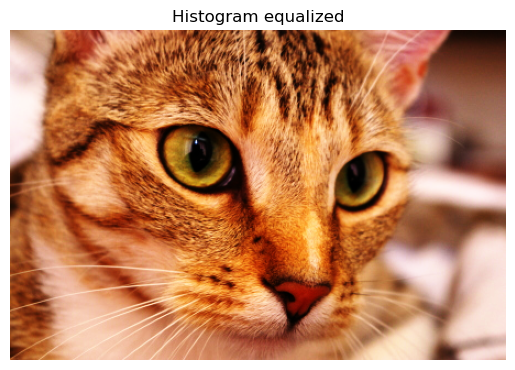

In [9]:
from skimage import exposure
cat_image = data.chelsea()
#obtain the equalized image
image_eq = exposure.equalize_hist(cat_image)
show_image(cat_image, 'Original')
show_image(image_eq, 'Histogram equalized')

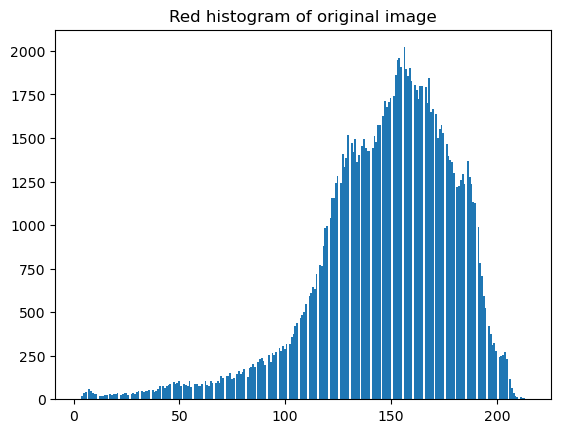

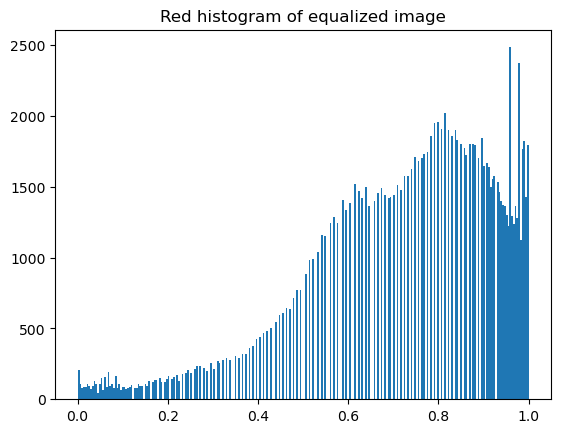

In [10]:
# red histogram
# original image
red_cat = cat_image[:, :, 0]
plt.hist(red_cat.ravel(), bins=256)
plt.title('Red histogram of original image')
plt.show()

# equalized image
red_eq = image_eq[:, :, 0]
plt.hist(red_eq.ravel(), bins=256)
plt.title('Red histogram of equalized image')
plt.show()

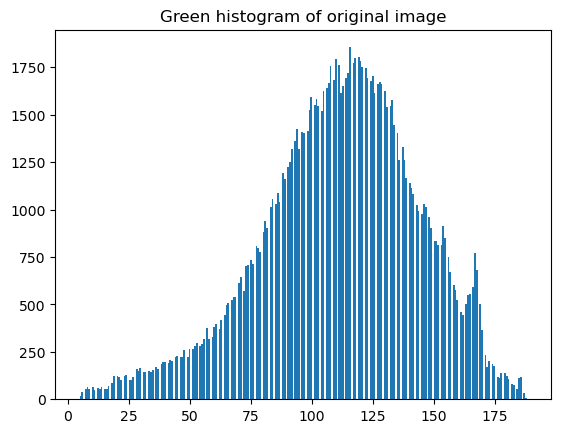

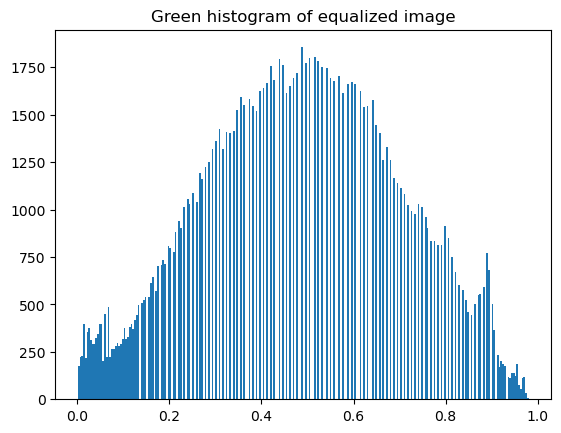

In [11]:
# green histogram
# original image
green_cat = cat_image[:, :, 1]
plt.hist(green_cat.ravel(), bins=256)
plt.title('Green histogram of original image')
plt.show()

# Equalized image
green_eq = image_eq[:, :, 1]
plt.hist(green_eq.ravel(), bins=256)
plt.title('Green histogram of equalized image')
plt.show()

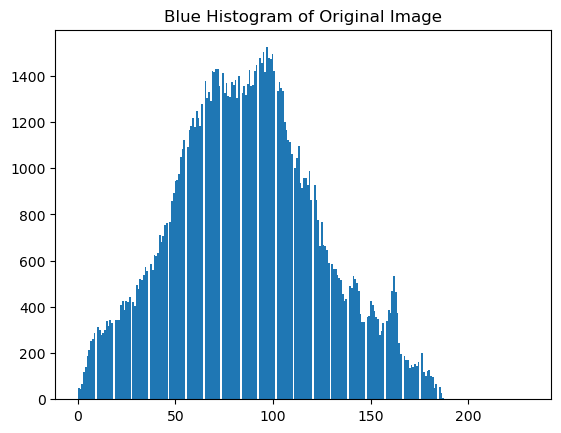

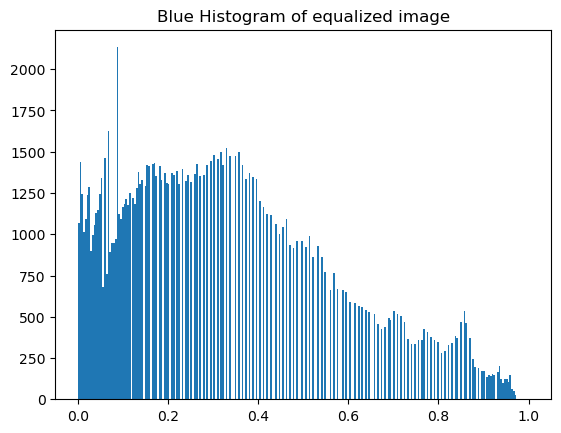

In [12]:
# Blue histogram
# original image
blue_cat = cat_image[:, :, 2]
plt.hist(blue_cat.ravel(), bins=256)
plt.title('Blue Histogram of Original Image')
plt.show()

# equalized image
blue_eq = image_eq[:, :, 2]
plt.hist(blue_eq.ravel(), bins=256)
plt.title('Blue Histogram of equalized image')
plt.show()

In [13]:
#adaptive histogram equalization
import numpy as np
np.max(cat_image) # obtain maximum pixel intensity of image


231

In [14]:
np.min(cat_image) # minimum intensity

0

In [15]:
np.max(image_eq)

1.0

In [16]:
np.min(image_eq)

0.0001157920670115792

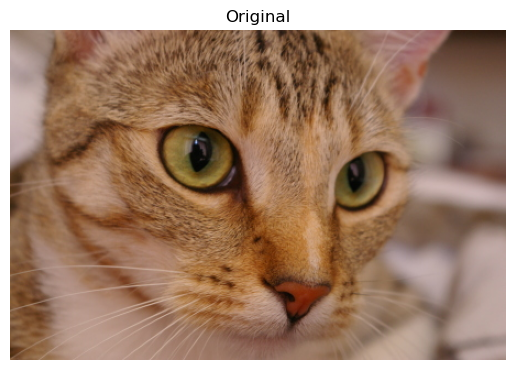

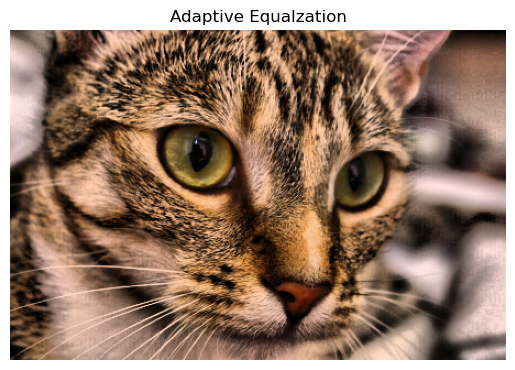

In [17]:

image_adaptive_eq = exposure.equalize_adapthist(cat_image, clip_limit=0.03)
show_image(cat_image, 'Original')
show_image(image_adaptive_eq, 'Adaptive Equalzation')

# Transforming images

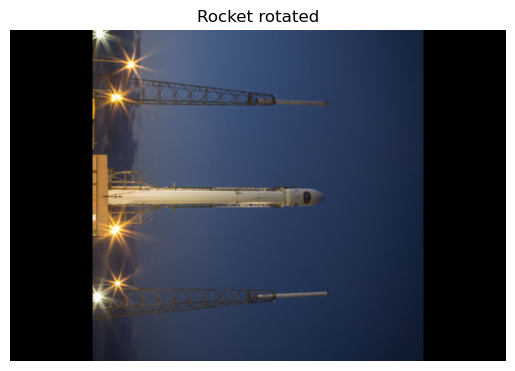

In [19]:
#Rotating
from skimage.transform import rotate, rescale, resize
rocket = data.rocket()
# Rotate the image 90 degrees clockwise
image_rotated = rotate(rocket, -90)
show_image(image_rotated, 'Rocket rotated')

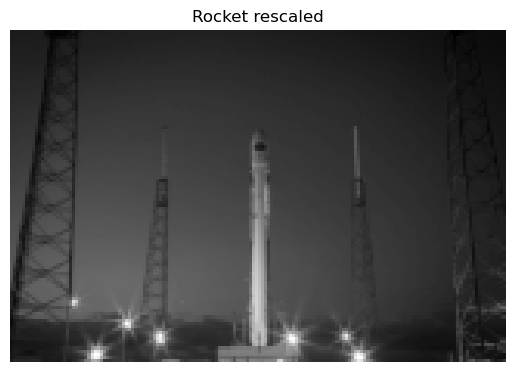

In [20]:
#Rescaling
#Rescale the image to be 4 times smaller
image_rescaled = rescale(rocket, 1/4, anti_aliasing = True)
show_image(image_rescaled, 'Rocket rescaled')

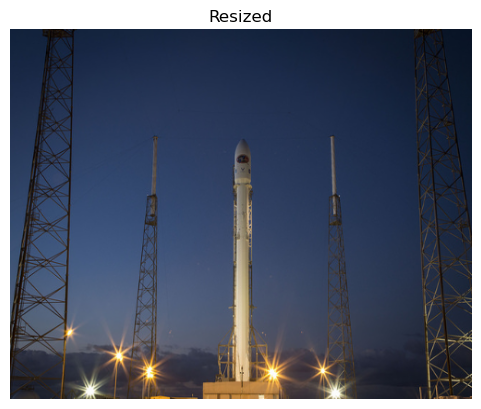

In [21]:
#Resizing
#height and width to resize
height = 400
width = 500
image_resized = resize(rocket, (height, width), anti_aliasing=True)
show_image(image_resized, "Resized")

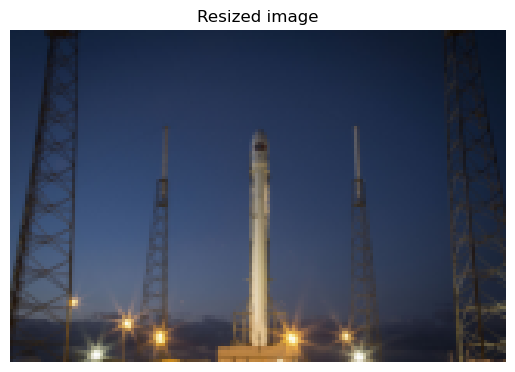

In [22]:
#Resizing proportionally
#set proportional height so its 4 times its size
height = rocket.shape[0]/4
width = rocket.shape[1]/4
image_resized = resize(rocket, (height, width), anti_aliasing=True)
show_image(image_resized, "Resized image")

## Morphological Filtering

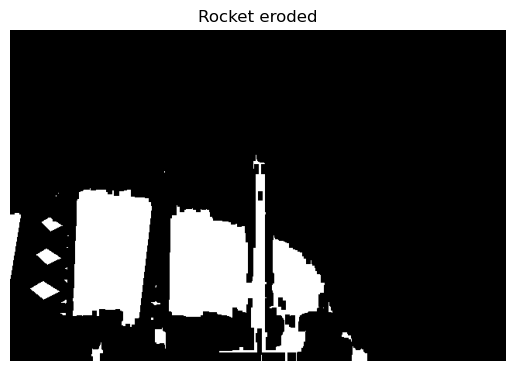

In [24]:
#Erosion in scikit-image
from skimage import morphology, color
#set structuring element to the rectangular shaped 
selem = morphology.rectangle(12, 6)
# convert image to grayscale
gray_rocket = color.rgb2gray(rocket)
# import the otsu threshold function
from skimage.filters import threshold_otsu
# obtain the optimal threshold value
thresh = threshold_otsu(gray_rocket)
# apply thresholding to the image
binary_rocket = gray_rocket > thresh
#obtain the crosed image with binary erosion
eroded_image = morphology.binary_erosion(binary_rocket, selem)
show_image(eroded_image, "Rocket eroded")

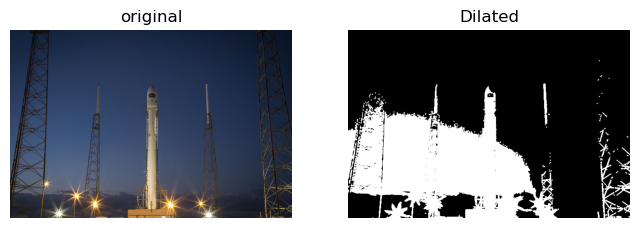

In [25]:
#Dilation 
dilated_image = morphology.binary_dilation(binary_rocket)
plot_comparison(rocket, dilated_image, 'Dilated')

## Image Restoration

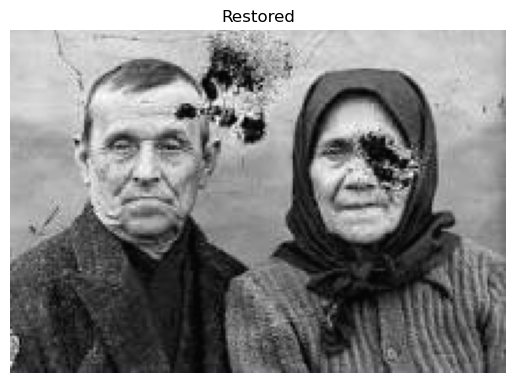

In [34]:
from skimage.restoration import inpaint
#obtain the mask
defect_image = plt.imread('images/defect-image.jpg')

def get_mask(image, threshold=5):
    """
    Creates a mask where pixels darker than the threshold are marked as defects (1).
    Assumes image range is 0-255.
    """
    # 1. If image is color (RGB), average the channels or convert to grayscale
    # simple averaging: (R+G+B)/3
    if image.ndim == 3:
        intensity = np.mean(image, axis=2)
    else:
        intensity = image

    # 2. Create boolean mask: True where pixel is dark (defect), False otherwise
    mask = intensity < threshold
    
    # 3. Return as integers (0 and 1) which inpaint expects
    return mask.astype(int)
mask = get_mask(defect_image)
#apply inpainting to the damaged image using the mask
# CORRECT
restored_image = inpaint.inpaint_biharmonic(defect_image, mask, channel_axis=-1)
show_image(restored_image, "Restored")